# Iowa Housing Prices, Part I: Explanatory Modeling

Jose Mariano C. Leechiu

**PART I: EXPLANATORY MODELLING**

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("housing.txt")
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [ ]:
print(df.isnull().sum())

Id                 0
MSSubClass         0
MSZoning           0
LotFrontage      259
LotArea            0
                ... 
MoSold             0
YrSold             0
SaleType           0
SaleCondition      0
SalePrice          0
Length: 81, dtype: int64


In [ ]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(missing)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


**Missing value findings:**

PoolQC : most houses do not have a pool

MiscFeature : most houses do not have any of the following: an elevator, a tennis court, a second garage, or a shed over 100 sq ft

Alley : most houses do not have alley access

Fence : most houses do not have a fence

*  81 houses do not have a garage
*  1 house is missing its Electrical value

In [ ]:
# Deal with missing values:
none_cols = ["Alley", "PoolQC", "Fence", "MiscFeature", "FireplaceQu",
             "GarageType", "GarageFinish", "GarageQual", "GarageCond",
             "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"]

df[none_cols] = df[none_cols].fillna("None")

In [ ]:
# Show houses with a pool, the pool size, and the sale price
df.loc[df["PoolArea"] > 0, ["Id", "PoolArea", "SalePrice"]]

,Id,PoolArea,SalePrice
197,198,512,235000
810,811,648,181000
1170,1171,576,171000
1182,1183,555,745000
1298,1299,480,160000
1386,1387,519,250000
1423,1424,738,274970


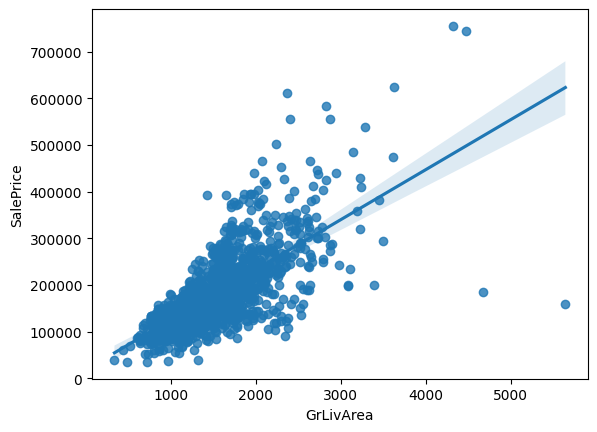

In [ ]:
# ABOVE GROUND LIVING AREA TO SALE PRICE
import statsmodels.api as sm

# choose variable to compare to sale price
sns.regplot(data=df, x="GrLivArea", y="SalePrice")
plt.show()

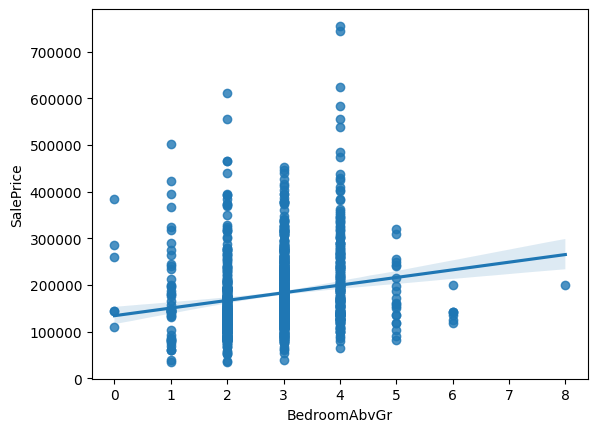

In [ ]:
# BEDROOMS TO SALE PRICE
import statsmodels.api as sm

# choose variable to compare to sale price
sns.regplot(data=df, x="BedroomAbvGr", y="SalePrice") # doesn't include basement bedrooms
plt.show()

In [ ]:
import numpy as np

# Columns where NaN genuinely means 'None' or 'No' for categorical features
# these are made from the missing data
none_cols_fill_na = [
    'Alley', 'PoolQC', 'Fence', 'MiscFeature', 'FireplaceQu', 'MasVnrType',
    'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
    'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2'
]
for col in none_cols_fill_na:
    df[col] = df[col].fillna('NA')

# Columns where NaN likely means '0' or absence
numerical_fill_zero = ['LotFrontage', 'MasVnrArea', 'GarageYrBlt']
for col in numerical_fill_zero:
    df[col] = df[col].fillna(0)

# Electrical column has only 1 missing value, fill it with the mode
# House without electricity?
if 'Electrical' in df.columns and df['Electrical'].isnull().any():
    df['Electrical'] = df['Electrical'].fillna(df['Electrical'].mode()[0])

# check that all missing values have been handled
print('Missing values after cleaning:')
print(df.isnull().sum().sum())

Missing values after cleaning:
0


In [ ]:
#EDA Time:
print(df["SalePrice"].describe())

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


In [ ]:
print(df.shape)

df.info()

(1460, 81)
<bound method DataFrame.info of         Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0        1          60       RL         65.0     8450   Pave  None      Reg   
1        2          20       RL         80.0     9600   Pave  None      Reg   
2        3          60       RL         68.0    11250   Pave  None      IR1   
3        4          70       RL         60.0     9550   Pave  None      IR1   
4        5          60       RL         84.0    14260   Pave  None      IR1   
...    ...         ...      ...          ...      ...    ...   ...      ...   
1455  1456          60       RL         62.0     7917   Pave  None      Reg   
1456  1457          20       RL         85.0    13175   Pave  None      Reg   
1457  1458          70       RL         66.0     9042   Pave  None      Reg   
1458  1459          20       RL         68.0     9717   Pave  None      Reg   
1459  1460          20       RL         75.0     9937   Pave  None      Reg   

     Lan

In [ ]:
df.head()

<bound method NDFrame.head of         Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0        1          60       RL         65.0     8450   Pave  None      Reg   
1        2          20       RL         80.0     9600   Pave  None      Reg   
2        3          60       RL         68.0    11250   Pave  None      IR1   
3        4          70       RL         60.0     9550   Pave  None      IR1   
4        5          60       RL         84.0    14260   Pave  None      IR1   
...    ...         ...      ...          ...      ...    ...   ...      ...   
1455  1456          60       RL         62.0     7917   Pave  None      Reg   
1456  1457          20       RL         85.0    13175   Pave  None      Reg   
1457  1458          70       RL         66.0     9042   Pave  None      Reg   
1458  1459          20       RL         68.0     9717   Pave  None      Reg   
1459  1460          20       RL         75.0     9937   Pave  None      Reg   

     LandContour Util

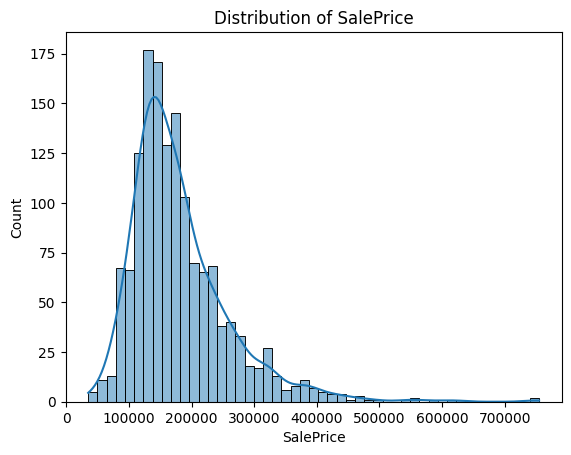

In [ ]:
# Plotting prices
sns.histplot(df["SalePrice"], kde=True)
plt.title("Distribution of SalePrice")
plt.show()

OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64


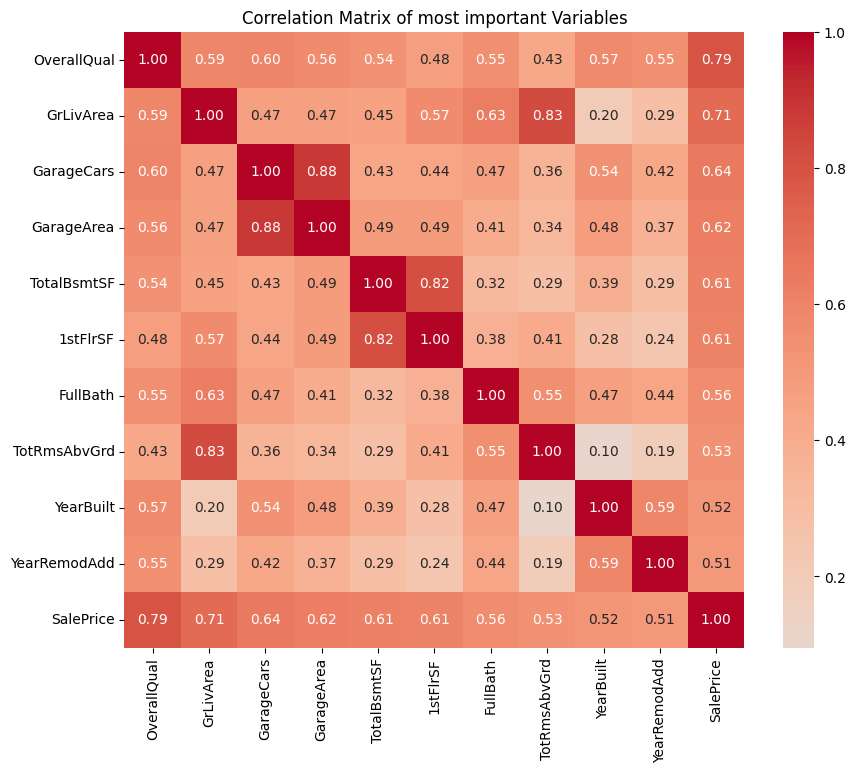

In [ ]:
# Which variables affect sale price the most?
# correlation matrix?

num = df.select_dtypes("number").drop(columns="Id")
corrMatrix = num.corr()["SalePrice"].drop("SalePrice").sort_values(ascending=False)
print(corrMatrix.head(10))

# Heatmap of the top 10
top10 = corrMatrix.abs().sort_values(ascending=False).head(10).index.tolist() + ["SalePrice"]
plt.figure(figsize=(10, 8))
sns.heatmap(num[top10].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix of the Most Important Variables"); plt.show()

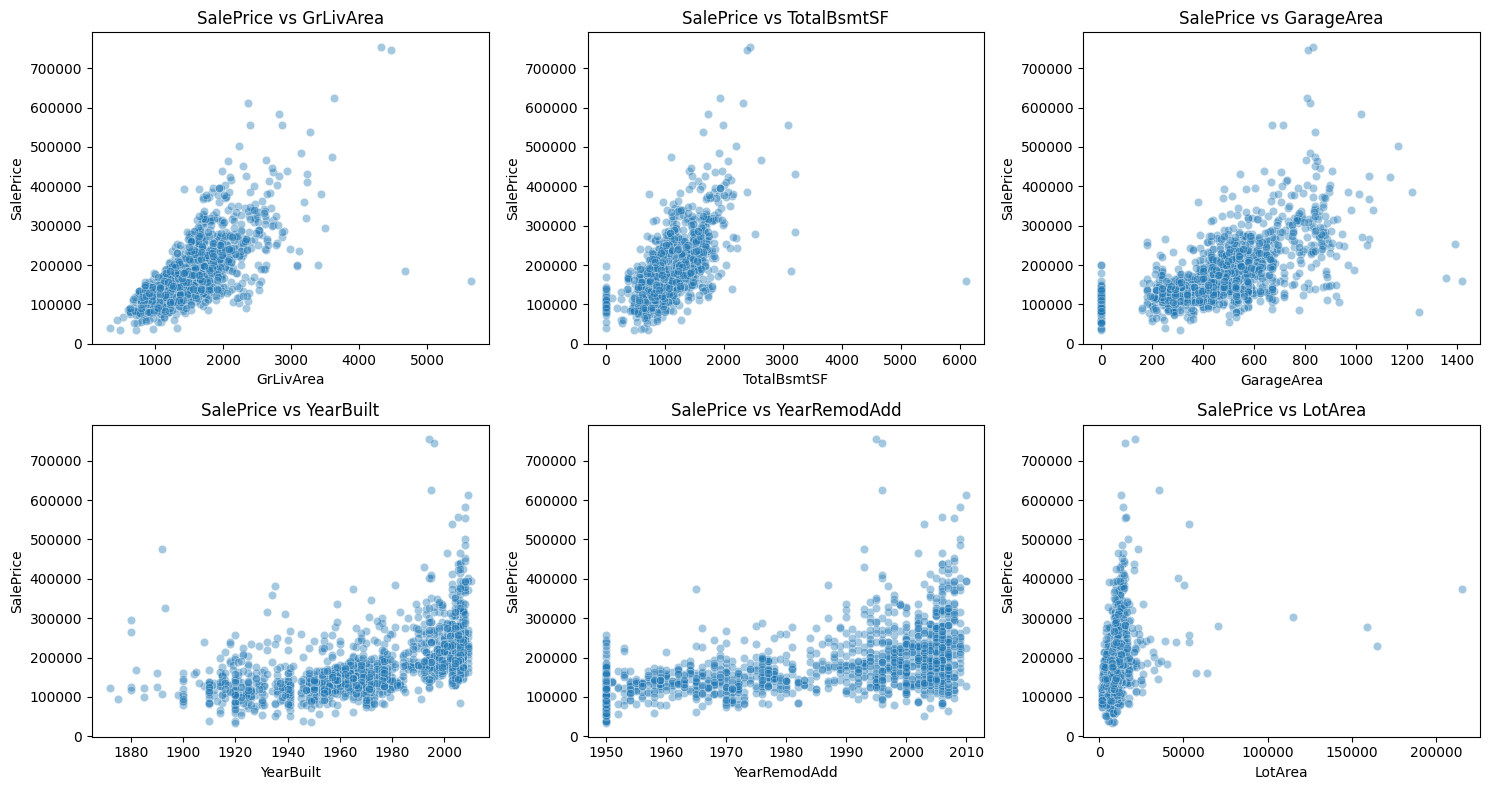

In [ ]:
# Plot Sales price with key numerical variables
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, ["GrLivArea", "TotalBsmtSF", "GarageArea",
                               "YearBuilt", "YearRemodAdd", "LotArea"]):
    sns.scatterplot(x=df[col], y=df["SalePrice"], alpha=0.4, ax=ax)
    ax.set_title(f"SalePrice vs {col}")
plt.tight_layout(); plt.show()

There seems to be a positive relationship with all of them except for the Lot area, likely because very few listings have lots larger than 50,000 sq ft.

I asked Gemini to make this comparison for fun, and it's interesting following today's class, where Importance != Significance.

/tmp/ipykernel_3904/3766453727.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Importance", y="Feature", data=fi_df, palette="viridis")


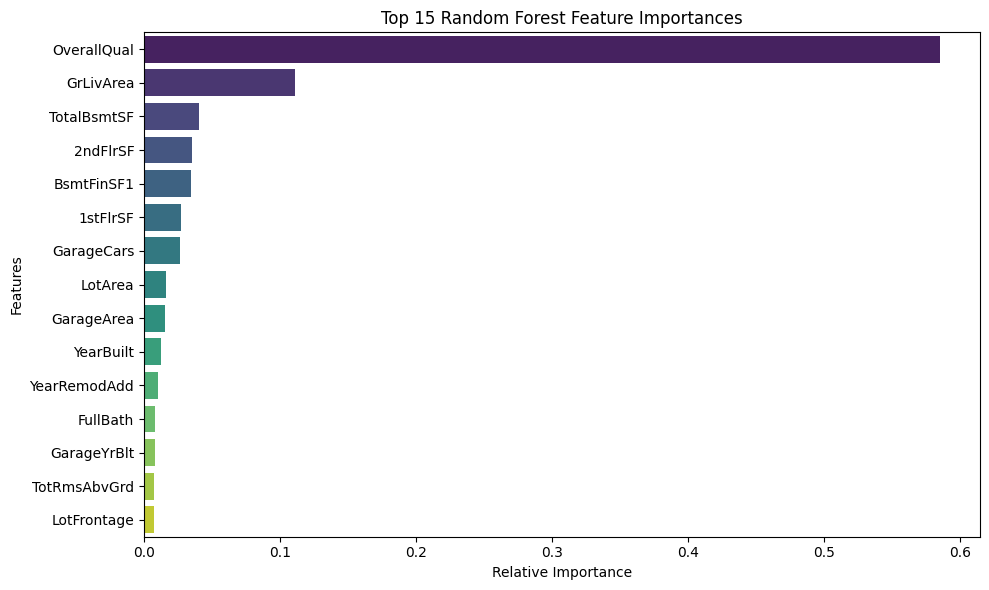

In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Prepare numeric features (excluding ID and target)
X_rf = df.select_dtypes("number").drop(columns=["Id", "SalePrice"])
y_rf = df["SalePrice"]

# Train Random Forest
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_rf, y_rf)

# Get feature importances
importances = rf.feature_importances_
feature_names = X_rf.columns

# Create a DataFrame and sort
fi_df = pd.DataFrame({"Feature": feature_names, "Importance": importances})
fi_df = fi_df.sort_values(by="Importance", ascending=False).head(15)

# Plot feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x="Importance", y="Feature", data=fi_df, palette="viridis")
plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Relative Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()


In [ ]:
#Part 2
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression

morty_df = pd.read_csv('Morty.txt')
morty_row = morty_df.iloc[0]

morty_features = {
    'GrLivArea' : morty_row['GrLivArea'],
    'OverallQual' : morty_row['OverallQual'],
    'YearBuilt' : morty_row['YearBuilt'],
    'FullBath' : morty_row['FullBath'],
    'GarageCars' : morty_row['GarageCars'],
}

feature_order = ["GrLivArea", "OverallQual", "YearBuilt", "FullBath", "GarageCars"]

# Train a linear regression model to get the intercept and coefficients
X = df[feature_order]
y = df["SalePrice"]

model = LinearRegression()
model.fit(X, y)

intercept = model.intercept_
coefficients = dict(zip(feature_order, model.coef_))

# Calculate predicted price
predicted_price = intercept
for feat in feature_order:
  feat_val = morty_features[feat]
  coef = coefficients[feat]
  predicted_price += feat_val * coef

print(f"Predicted Price: {predicted_price:.2f}")

difference = predicted_price - morty_row['SalePrice']
print(f"Difference: {difference:.2f}")

Predicted Price: 164257.79
Difference: 21257.79


Our estimate for Morty's house is $164,257.79. The difference in sale price from the other firm is $21,257.79.

3 significant changes Morty should do to his house to increase value:

*  Add another bedroom
*  Add another bathroom
*  Make the garage bigger